# Comparative Bayesian Models for Stroke Dataset Analysis

**Course:** Intelligent Systems II  
**Project type:** Bayesian probability, graphical models, inference and model comparison  
**Team project:** Four members, four Bayesian approaches

## Objective

This notebook compares four approaches on the same public stroke dataset and the same held-out test split:

1. **Categorical Naive Bayes** — assumes features are conditionally independent given the outcome.
2. **Expert Bayesian Network** — uses a clearly documented, manually specified graph and learned conditional probability tables.
3. **Compact Bayesian Network** — uses a simpler graph to study how the assumed dependencies affect inference.
4. **Strong-prior Bayesian Network** — keeps the expert graph but applies stronger Dirichlet smoothing to explore prior sensitivity.

The last approach is a prior-sensitivity variant of the expert network, not a completely separate model family. The goal is a fair, explainable classroom comparison rather than a clinical prediction system.

**Important:** This dataset is imbalanced and this project is educational only. The outputs are not a medical diagnosis or a validated clinical risk score.

## 1. Setup and imports

Run the notebook from the project folder or open it in Jupyter. The CSV and shared Python module are included in the project ZIP.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from bayes_core import (
    load_and_prepare, build_models, evaluate_models, save_bundle,
    FEATURES, TARGET, EXPERT_EDGES, COMPACT_EDGES, STATE_VALUES,
    evidence_from_patient, predict_model
)

DATA_PATH = PROJECT_ROOT / "data" / "healthcare-dataset-stroke-data.csv"
MODEL_PATH = PROJECT_ROOT / "models" / "bayesian_models.joblib"

## 2. Load and understand the data

We remove the patient identifier because it should not help predict the outcome. Missing BMI values are filled with the median. Age, glucose and BMI are converted into meaningful categories for discrete Bayesian-network inference.

In [2]:
raw_df = pd.read_csv(DATA_PATH)
print(f"Rows: {len(raw_df):,} | Columns: {raw_df.shape[1]}")
display(raw_df.head())

missing = raw_df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("Missing values"))

print("Stroke outcome counts:")
display(raw_df["stroke"].value_counts().rename(index={0: "No stroke", 1: "Stroke"}).to_frame("Count"))

Rows: 5,110 | Columns: 12


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


,Missing values
bmi,201


Stroke outcome counts:


,Count
stroke,
No stroke,4861
Stroke,249


C:\Users\amuly\AppData\Local\Temp\ipykernel_4508\2308400509.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  raw_df.groupby(pd.cut(raw_df["age"], [0, 18, 45, 65, 120], labels=["0–18", "19–45", "46–65", "66+"]))["stroke"].mean().plot(kind="bar", ax=axes[1])


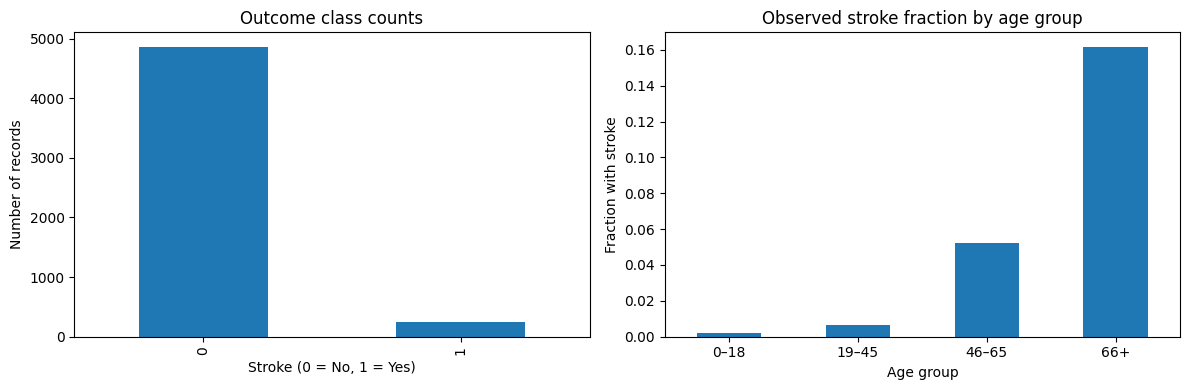

The outcome is imbalanced, so accuracy alone is not enough to evaluate the models.


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
raw_df["stroke"].value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Outcome class counts")
axes[0].set_xlabel("Stroke (0 = No, 1 = Yes)")
axes[0].set_ylabel("Number of records")
raw_df.groupby(pd.cut(raw_df["age"], [0, 18, 45, 65, 120], labels=["0–18", "19–45", "46–65", "66+"]))["stroke"].mean().plot(kind="bar", ax=axes[1])
axes[1].set_title("Observed stroke fraction by age group")
axes[1].set_xlabel("Age group")
axes[1].set_ylabel("Fraction with stroke")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print("The outcome is imbalanced, so accuracy alone is not enough to evaluate the models.")

## 3. Prepare modelling features

The same prepared rows and feature definitions are used by all four approaches. We use a stratified train/test split so the proportion of stroke cases is approximately preserved in both sets. The test data is not used to fit the models.

In [4]:
data = load_and_prepare(DATA_PATH)
train_df, test_df = train_test_split(
    data, test_size=0.25, random_state=42, stratify=data[TARGET]
)
print("Prepared data:", data.shape)
print("Training rows:", len(train_df), "| Test rows:", len(test_df))
print("Training stroke rate:", round(train_df[TARGET].mean(), 4))
print("Test stroke rate:", round(test_df[TARGET].mean(), 4))
display(data.head())

Prepared data: (5110, 8)
Training rows: 3832 | Test rows: 1278
Training stroke rate: 0.0488
Test stroke rate: 0.0485


,age_group,glucose_group,bmi_group,hypertension,heart_disease,gender,smoking_status,stroke
0,Senior,High,High,0,1,Male,formerly smoked,1
1,Senior,High,High,0,0,Female,never smoked,1
2,Senior,Elevated,High,0,1,Male,never smoked,1
3,Senior,High,High,0,0,Female,smokes,1
4,Senior,High,Normal,1,0,Female,never smoked,1


## 4. Model 1 — Categorical Naive Bayes

Categorical Naive Bayes estimates the class prior and each feature's conditional probability given the class. Its main simplifying assumption is that features are conditionally independent once the stroke outcome is known. We use categorical features so this model can be compared with the discrete Bayesian networks.

In [5]:
# Fit all four approaches using training data only.
bundle = build_models(train_df)
print("Models fitted:")
for model_name in bundle["models"]:
    print(" •", model_name)

Models fitted:
 • Categorical Naive Bayes
 • Expert Bayesian Network
 • Compact Bayesian Network
 • Strong-Prior Bayesian Network


## 5. Model 2 — Expert Bayesian Network

This graph is specified using an explicit set of modelling assumptions. Conditional probability tables are estimated from training data with Dirichlet smoothing. The arrows express the chosen statistical structure; they should not be interpreted as proven causal relationships.

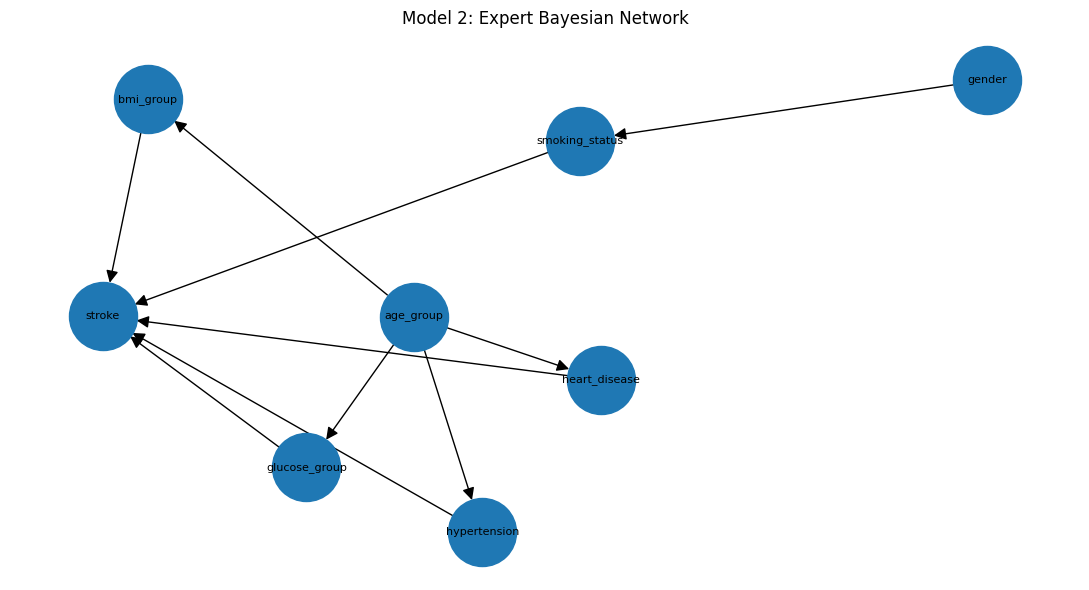

In [6]:
def draw_network(edges, title):
    graph = nx.DiGraph()
    graph.add_nodes_from(FEATURES + [TARGET])
    graph.add_edges_from(edges)
    position = nx.spring_layout(graph, seed=12, k=1.1)
    plt.figure(figsize=(11, 6))
    nx.draw_networkx(
        graph, position, with_labels=True, node_size=2400,
        font_size=8, arrows=True, arrowsize=18
    )
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

draw_network(EXPERT_EDGES, "Model 2: Expert Bayesian Network")

## 6. Model 3 — Compact Bayesian Network

The compact network connects each feature directly to the outcome. This is a simpler structure, making it useful to compare how the network design affects the estimated posterior probabilities.

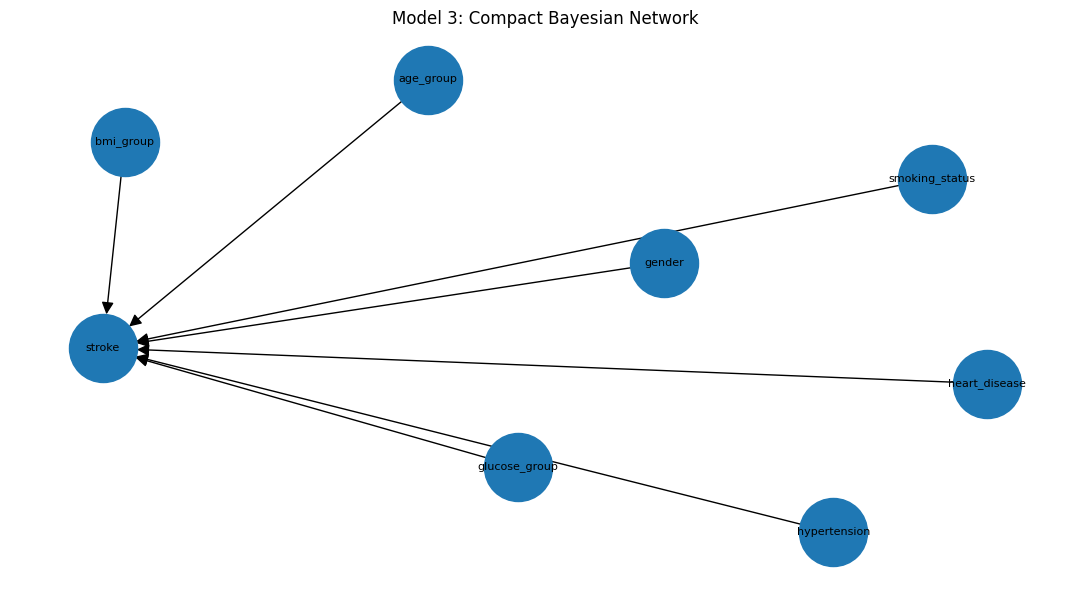

In [7]:
draw_network(COMPACT_EDGES, "Model 3: Compact Bayesian Network")

## 7. Model 4 — Stronger prior smoothing

This version uses the expert graph with a larger Dirichlet pseudo-count (`alpha=5` rather than `alpha=1`). Smoothing prevents zero probabilities in rare feature combinations. Comparing the two versions shows whether stronger smoothing changes the inferred probabilities.

In [8]:
print("Model 4 uses the expert graph with stronger smoothing.")
print("Expert graph edges:", len(EXPERT_EDGES))
print("Compact graph edges:", len(COMPACT_EDGES))

Model 4 uses the expert graph with stronger smoothing.
Expert graph edges: 10
Compact graph edges: 7


## 8. Evaluate all four approaches on the same test set

We report accuracy, precision, recall, F1, ROC-AUC and PR-AUC. PR-AUC is particularly useful to inspect when the positive class is rare. Metrics are computed on the held-out test data; the threshold for class predictions is 0.5 for this simple comparison.

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Categorical Naive Bayes,0.933,0.214,0.145,0.173,0.788,0.151
1,Expert Bayesian Network,0.950,0.375,0.048,0.086,0.729,0.149
2,Compact Bayesian Network,0.930,0.091,0.048,0.063,0.713,0.102
3,Strong-Prior Bayesian Network,0.950,0.375,0.048,0.086,0.715,0.144


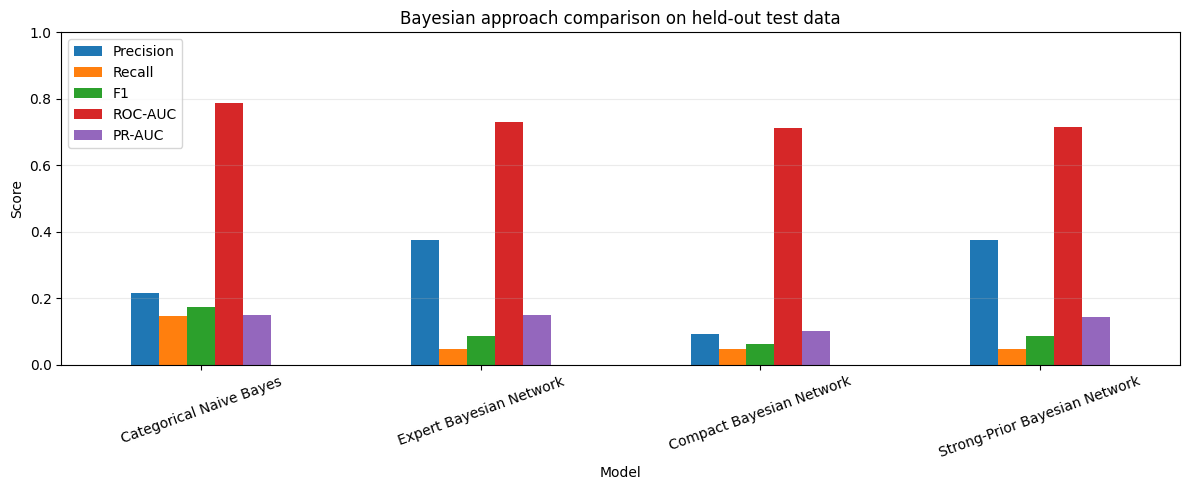

In [9]:
metrics, probability_outputs = evaluate_models(bundle, test_df)
metric_columns = ["Model", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
display(metrics[metric_columns].style.format({col: "{:.3f}" for col in metric_columns if col != "Model"}))

fig, ax = plt.subplots(figsize=(12, 5))
metrics.set_index("Model")[ ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"] ].plot(kind="bar", ax=ax)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Bayesian approach comparison on held-out test data")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

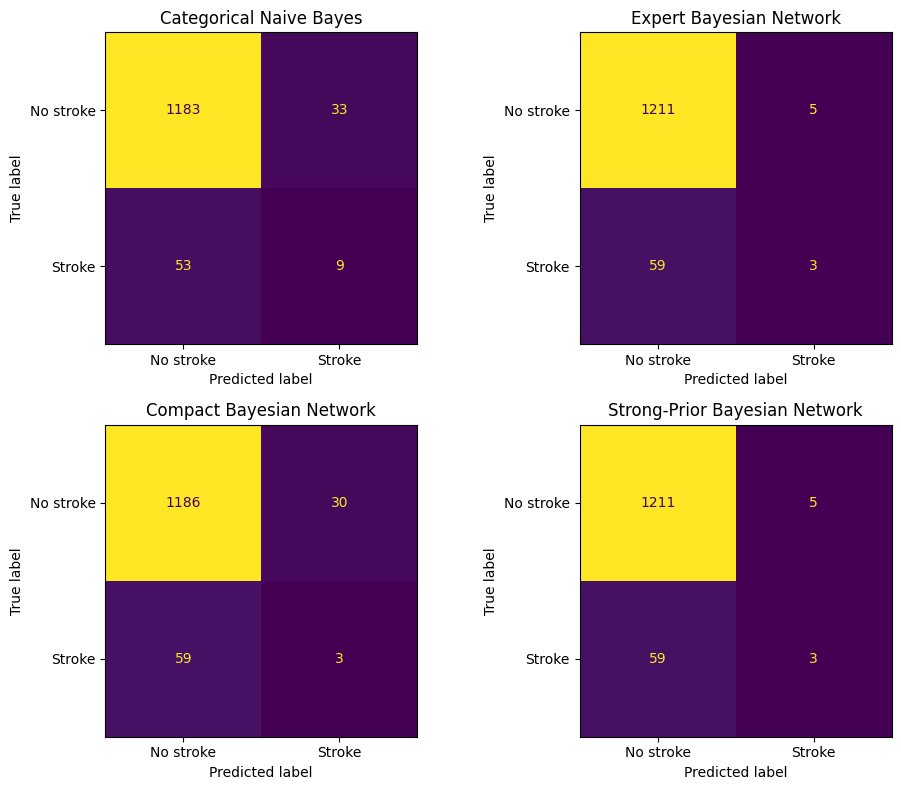

In [10]:
# Confusion matrix for each model, using the same test observations.
y_true = test_df[TARGET].to_numpy()
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (_, row) in zip(axes.flat, metrics.iterrows()):
    matrix = np.array(row["Confusion Matrix"])
    disp = ConfusionMatrixDisplay(matrix, display_labels=["No stroke", "Stroke"])
    disp.plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(row["Model"])
plt.tight_layout()
plt.show()

## 9. Example Bayesian inference

We compare posterior estimates for one illustrative profile. The profile is a demonstration input, not a medical assessment. Since the models make different assumptions, their estimates may differ.

Evidence supplied to the discrete models:
{'age_group': 'Senior', 'glucose_group': 'Elevated', 'bmi_group': 'High', 'hypertension': 1, 'heart_disease': 0, 'gender': 'Female', 'smoking_status': 'formerly smoked'}


,Model,Estimated probability (%)
0,Categorical Naive Bayes,27.383305
1,Expert Bayesian Network,21.428571
2,Compact Bayesian Network,25.000000
3,Strong-Prior Bayesian Network,31.818182


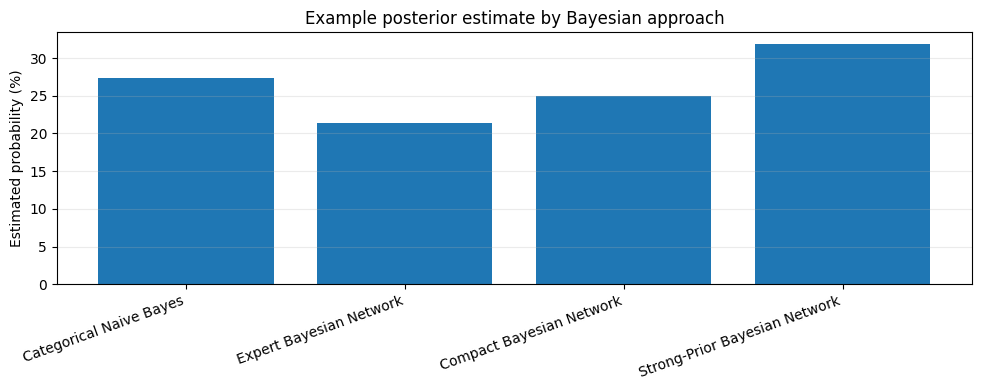

In [11]:
example_patient = {
    "age": 67,
    "avg_glucose_level": 145,
    "bmi": 29,
    "hypertension": 1,
    "heart_disease": 0,
    "gender": "Female",
    "smoking_status": "formerly smoked",
}
evidence = evidence_from_patient(example_patient)
print("Evidence supplied to the discrete models:")
print(evidence)

example_probabilities = {
    name: 100 * predict_model(bundle, name, evidence)
    for name in bundle["models"]
}
display(pd.DataFrame({"Model": example_probabilities.keys(), "Estimated probability (%)": example_probabilities.values()}))

plt.figure(figsize=(10, 4))
plt.bar(example_probabilities.keys(), example_probabilities.values())
plt.ylabel("Estimated probability (%)")
plt.title("Example posterior estimate by Bayesian approach")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 10. Prior sensitivity experiment

Compare the expert network with its stronger-prior variant over the same set of example profiles. This is an experiment about assumptions, not a claim that one prior is universally correct.

,Profile,Expert BN (%),Strong-prior BN (%)
0,Example 1,3.54,5.34
1,Example 2,21.43,31.82
2,Example 3,80.00,61.54


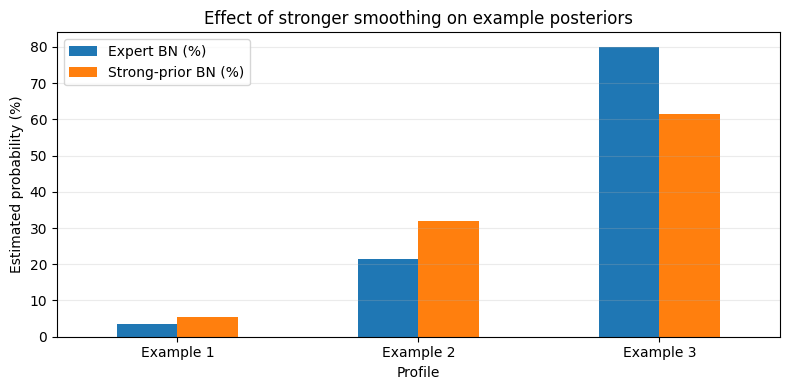

In [12]:
profiles = [
    {"age": 35, "avg_glucose_level": 90, "bmi": 22, "hypertension": 0, "heart_disease": 0, "gender": "Female", "smoking_status": "never smoked"},
    {"age": 58, "avg_glucose_level": 145, "bmi": 29, "hypertension": 1, "heart_disease": 0, "gender": "Male", "smoking_status": "formerly smoked"},
    {"age": 78, "avg_glucose_level": 210, "bmi": 32, "hypertension": 1, "heart_disease": 1, "gender": "Female", "smoking_status": "smokes"},
]
sensitivity_rows = []
for index, profile in enumerate(profiles, start=1):
    case_evidence = evidence_from_patient(profile)
    sensitivity_rows.append({
        "Profile": f"Example {index}",
        "Expert BN (%)": 100 * predict_model(bundle, "Expert Bayesian Network", case_evidence),
        "Strong-prior BN (%)": 100 * predict_model(bundle, "Strong-Prior Bayesian Network", case_evidence),
    })
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity.round(2))
sensitivity.set_index("Profile").plot(kind="bar", figsize=(8, 4))
plt.ylabel("Estimated probability (%)")
plt.title("Effect of stronger smoothing on example posteriors")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 11. Save models and results for the API and Streamlit app

This cell writes the fitted models to `models/bayesian_models.joblib` and the held-out evaluation table to `models/evaluation_metrics.csv`. The FastAPI service and Streamlit dashboard load these files; they do not retrain the models when each request arrives.

In [13]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
save_bundle(bundle, MODEL_PATH)
metrics.drop(columns=["Confusion Matrix"]).to_csv(PROJECT_ROOT / "models" / "evaluation_metrics.csv", index=False)
with open(PROJECT_ROOT / "models" / "confusion_matrices.json", "w", encoding="utf-8") as file:
    json.dump({row["Model"]: row["Confusion Matrix"] for _, row in metrics.iterrows()}, file, indent=2)
print("Saved model bundle:", MODEL_PATH)
print("Saved evaluation metrics:", PROJECT_ROOT / "models" / "evaluation_metrics.csv")

Saved model bundle: c:\Amulya\Projects\Bayesian_Stroke_Comparison_Project\models\bayesian_models.joblib
Saved evaluation metrics: c:\Amulya\Projects\Bayesian_Stroke_Comparison_Project\models\evaluation_metrics.csv


## 12. Conclusion

- Categorical Naive Bayes provides a useful baseline with a strong conditional-independence assumption.
- The expert and compact Bayesian networks make different structural assumptions and can therefore return different posterior estimates.
- Stronger Dirichlet smoothing changes how much rare combinations influence the estimated conditional probabilities.
- Because the data is imbalanced, recall and PR-AUC should be considered alongside precision, F1 and ROC-AUC.
- The experiment does not establish clinical usefulness or causality. A responsible medical application would require external validation, calibration analysis and expert review.